# IBM Applied Data Science Capstone — SpaceX Falcon 9 Landing Prediction

**Beginner-friendly starter notebook**

This notebook covers the basic workflow: load the SpaceX launch dataset, inspect and clean it, explore patterns with charts, and train a simple classification model to predict whether a Falcon 9 first stage landed successfully.

> **Important:** This is a starter project. Run the cells and use the actual outputs from your run in your report. Do not claim results that you have not verified. If the dataset URL is unavailable, download `dataset_part_2.csv` from the IBM Skills Network course materials and place it beside this notebook.


## 1. Project objective

SpaceX can reduce launch costs by reusing the Falcon 9 first stage. The goal is to explore launch data and build a baseline model that predicts the landing outcome (`Class`).

**Questions explored**
- How many launches are included in the dataset?
- How do launch outcomes vary by launch site and payload mass?
- Does the dataset show changes in landing success over time?
- How well can a basic classification model predict the landing outcome?

**Tools:** Python, pandas, NumPy, Matplotlib, seaborn, and scikit-learn.


In [1]:
# 2. Import libraries
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

try:
    import seaborn as sns
    HAS_SEABORN = True
except ImportError:
    HAS_SEABORN = False

from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 3. Load the dataset

The notebook first tries the public IBM Skills Network dataset URL. If that fails, it looks for a local file named `dataset_part_2.csv`.

If neither source is available, download the CSV from the course lab materials and save it in the same folder as this notebook.


In [2]:
from pathlib import Path

DATA_URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv"
LOCAL_FILE = Path("dataset_part_2.csv")

try:
    df = pd.read_csv(DATA_URL)
    print("Dataset loaded from the IBM Skills Network URL.")
except Exception as e:
    if LOCAL_FILE.exists():
        df = pd.read_csv(LOCAL_FILE)
        print("Online download failed; loaded local dataset_part_2.csv instead.")
    else:
        raise RuntimeError(
            "Could not download the dataset. Download dataset_part_2.csv from the IBM course materials "
            "and place it in the same folder as this notebook, then rerun this cell."
        ) from e

print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded from the IBM Skills Network URL.
Dataset shape: (90, 18)


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


## 4. Understand the data

Check column names, data types, missing values, and summary statistics before analysis.


In [3]:
print("Columns:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values per column:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nNumeric summary:")
display(df.describe(include="all").T)

Columns:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   FlightNumber    90 non-null     int64  
 1   Date            90 non-null     str    
 2   BoosterVersion  90 non-null     str    
 3   PayloadMass     90 non-null     float64
 4   Orbit           90 non-null     str    
 5   LaunchSite      90 non-null     str    
 6   Outcome         90 non-null     str    
 7   Flights         90 non-null     int64  
 8   GridFins        90 non-null     bool   
 9   Reused          90 non-null     bool   
 10  Legs            90 non-null     bool   
 11  LandingPad      64 non-null     str    
 12  Block           

,missing_count
LandingPad,26
FlightNumber,0
Date,0
BoosterVersion,0
Orbit,0
PayloadMass,0
Outcome,0
Flights,0
GridFins,0
LaunchSite,0



Numeric summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FlightNumber,90.0,NaN,NaN,NaN,45.5,26.124701,1.0,23.25,45.5,67.75,90.0
Date,90,90,2010-06-04,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BoosterVersion,90,1,Falcon 9,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PayloadMass,90.0,NaN,NaN,NaN,6104.959412,4694.67172,350.0,2510.75,4701.5,8912.75,15600.0
Orbit,90,11,GTO,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LaunchSite,90,3,CCAFS SLC 40,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outcome,90,8,True ASDS,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flights,90.0,NaN,NaN,NaN,1.788889,1.213172,1.0,1.0,1.0,2.0,6.0
GridFins,90,2,True,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reused,90,2,False,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Basic data preparation

The IBM dataset normally includes a binary target column named `Class`, where `1` indicates a successful landing and `0` indicates an unsuccessful landing. The code below checks that the target is present and prepares a copy for analysis.


In [4]:
if "Class" not in df.columns:
    raise ValueError("Expected target column 'Class' was not found. Check that you loaded dataset_part_2.csv.")

data = df.copy()

# Convert common numeric columns where possible.
for col in ["PayloadMass", "FlightNumber", "Flights", "Block", "ReusedCount", "Latitude", "Longitude"]:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Normalize target values to numeric 0/1.
data["Class"] = pd.to_numeric(data["Class"], errors="coerce")
data = data.dropna(subset=["Class"])
data["Class"] = data["Class"].astype(int)

print("Prepared dataset shape:", data.shape)
print("\nLanding outcome counts (0 = unsuccessful, 1 = successful):")
display(data["Class"].value_counts().sort_index().rename_axis("Class").to_frame("Launches"))

Prepared dataset shape: (90, 18)

Landing outcome counts (0 = unsuccessful, 1 = successful):


,Launches
Class,
0,30
1,60


## 6. Exploratory data analysis (EDA)

### 6.1 Landing outcome distribution
This chart shows the number of successful and unsuccessful landings in the dataset.


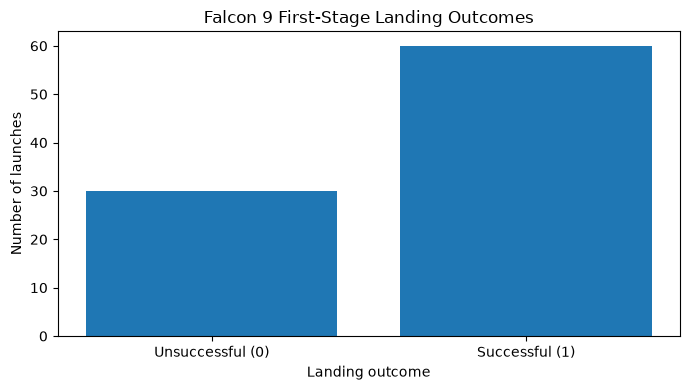

In [5]:
outcome_counts = data["Class"].value_counts().sort_index()
labels = ["Unsuccessful (0)", "Successful (1)"]
plot_labels = [labels[int(i)] if int(i) in [0, 1] else str(i) for i in outcome_counts.index]

plt.figure(figsize=(7, 4))
plt.bar(plot_labels, outcome_counts.values)
plt.title("Falcon 9 First-Stage Landing Outcomes")
plt.xlabel("Landing outcome")
plt.ylabel("Number of launches")
plt.tight_layout()
plt.show()

### 6.2 Success rate by launch site

The success rate is the mean of the binary `Class` variable. This chart compares observed rates across launch sites; sites with very few launches should be interpreted cautiously.


,launches,success_rate
LaunchSite,,
KSC LC 39A,22,0.772727
VAFB SLC 4E,13,0.769231
CCAFS SLC 40,55,0.600000


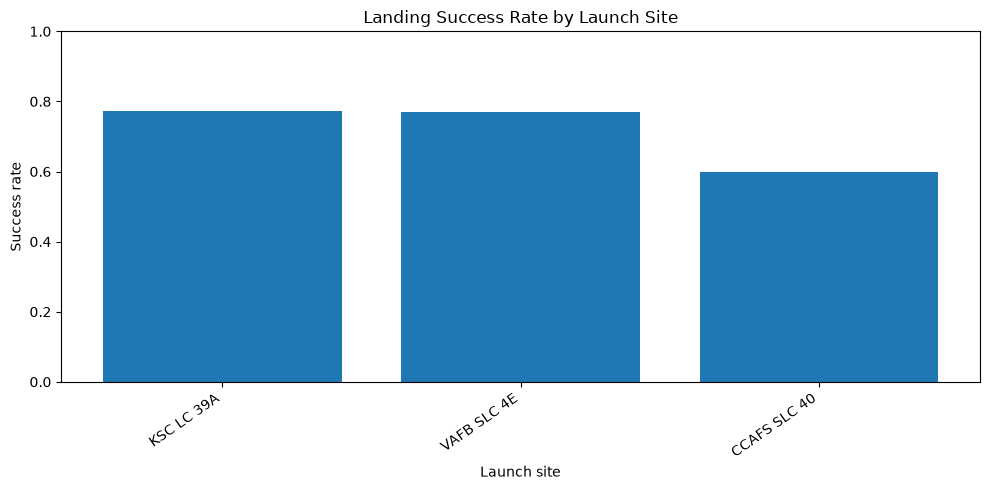

In [6]:
if "LaunchSite" in data.columns:
    site_summary = data.groupby("LaunchSite", dropna=False).agg(
        launches=("Class", "size"),
        success_rate=("Class", "mean")
    ).sort_values("success_rate", ascending=False)

    display(site_summary)

    plt.figure(figsize=(10, 5))
    plt.bar(site_summary.index.astype(str), site_summary["success_rate"])
    plt.title("Landing Success Rate by Launch Site")
    plt.xlabel("Launch site")
    plt.ylabel("Success rate")
    plt.ylim(0, 1)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("LaunchSite column not found; skipping this chart.")

### 6.3 Payload mass and landing outcome

Compare payload mass distributions for successful and unsuccessful landings. This is an exploratory comparison, not proof that payload mass causes an outcome.


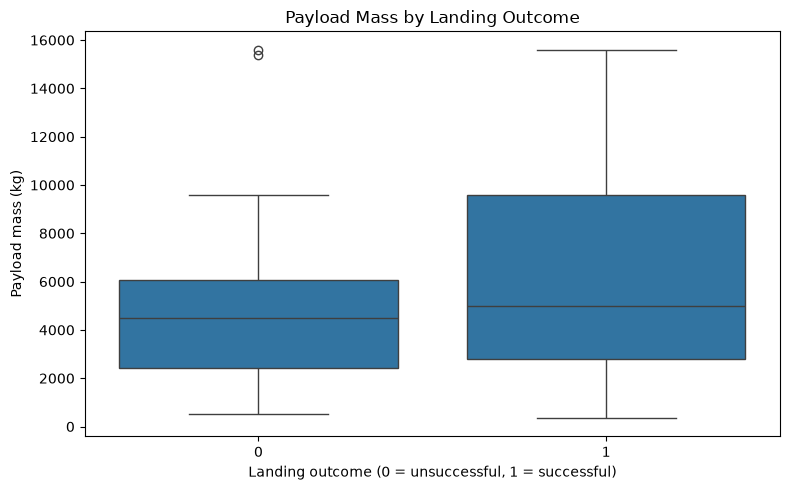

In [7]:
if "PayloadMass" in data.columns:
    payload_data = data.dropna(subset=["PayloadMass"])

    plt.figure(figsize=(8, 5))
    if HAS_SEABORN:
        sns.boxplot(data=payload_data, x="Class", y="PayloadMass")
    else:
        groups = [
            payload_data.loc[payload_data["Class"] == c, "PayloadMass"].values
            for c in sorted(payload_data["Class"].unique())
        ]
        plt.boxplot(groups, labels=[str(c) for c in sorted(payload_data["Class"].unique())])

    plt.title("Payload Mass by Landing Outcome")
    plt.xlabel("Landing outcome (0 = unsuccessful, 1 = successful)")
    plt.ylabel("Payload mass (kg)")
    plt.tight_layout()
    plt.show()
else:
    print("PayloadMass column not found; skipping this chart.")

### 6.4 Success rate over flight number

Flight number can act as a rough proxy for time/order. We compare the landing success rate in groups of flights.


,launches,success_rate
FlightGroup,,
"(0.999, 15.833]",15,0.200000
"(15.833, 30.667]",15,0.666667
"(30.667, 45.5]",15,0.866667
"(45.5, 60.333]",15,0.600000
"(60.333, 75.167]",15,0.733333
"(75.167, 90.0]",15,0.933333


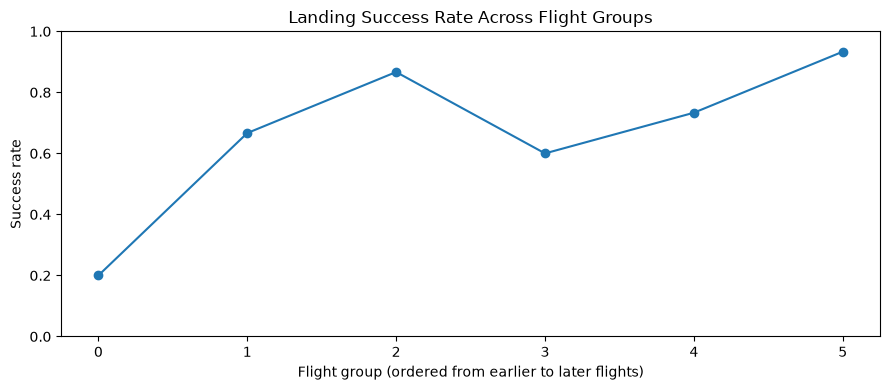

In [8]:
if "FlightNumber" in data.columns:
    flight_data = data.dropna(subset=["FlightNumber"]).copy()
    if not flight_data.empty:
        flight_data["FlightGroup"] = pd.qcut(
            flight_data["FlightNumber"],
            q=min(6, flight_data["FlightNumber"].nunique()),
            duplicates="drop"
        )
        trend = flight_data.groupby("FlightGroup", observed=False)["Class"].agg(["count", "mean"])
        display(trend.rename(columns={"count": "launches", "mean": "success_rate"}))

        plt.figure(figsize=(9, 4))
        plt.plot(range(len(trend)), trend["mean"], marker="o")
        plt.title("Landing Success Rate Across Flight Groups")
        plt.xlabel("Flight group (ordered from earlier to later flights)")
        plt.ylabel("Success rate")
        plt.ylim(0, 1)
        plt.tight_layout()
        plt.show()
else:
    print("FlightNumber column not found; skipping this chart.")

## 7. Prepare features for machine learning

We use a small, interpretable baseline model. Numeric and categorical predictors are handled in a preprocessing pipeline. The target `Class` is excluded from the input features to avoid data leakage.

Some columns may be identifiers or post-outcome information. For a rigorous project, review the features and only use information that would be available before a launch.


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Candidate features commonly available in this course dataset.
candidate_features = [
    "FlightNumber", "PayloadMass", "Flights", "GridFins", "Reused",
    "Legs", "Block", "ReusedCount", "Orbit", "LaunchSite", "Serial"
]
features = [c for c in candidate_features if c in data.columns]

if not features:
    raise ValueError("No expected feature columns were found. Inspect the dataset columns and update candidate_features.")

X = data[features].copy()
y = data["Class"].copy()

# Drop rows where the target is not binary, if any.
valid_target = y.isin([0, 1])
X = X.loc[valid_target]
y = y.loc[valid_target]

numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Features used:", features)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Rows available for modeling:", len(X))

Features used: ['FlightNumber', 'PayloadMass', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount', 'Orbit', 'LaunchSite', 'Serial']
Numeric features: ['FlightNumber', 'PayloadMass', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount']
Categorical features: ['Orbit', 'LaunchSite', 'Serial']
Rows available for modeling: 90


## 8. Train and compare baseline classification models

We compare logistic regression with a decision tree using a held-out test set. Results can vary with dataset versions and the train/test split. The test set is used only for evaluation, not training.


In [10]:
# Stratify preserves the class proportions in both sets when possible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=RANDOM_STATE)
}

results = []
fitted_models = {}

for name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 score": f1_score(y_test, predictions, zero_division=0)
    })
    fitted_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("F1 score", ascending=False)
display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 score
1,Decision Tree,0.870,0.875,0.933,0.903
0,Logistic Regression,0.826,0.789,1.000,0.882


## 9. Evaluate the best baseline model

The F1 score is used here to choose a model because it balances precision and recall. Always consider the context and class balance when selecting a metric.


Best baseline model by F1 score: Decision Tree

Classification report:
              precision    recall  f1-score   support

           0       0.86      0.75      0.80         8
           1       0.88      0.93      0.90        15

    accuracy                           0.87        23
   macro avg       0.87      0.84      0.85        23
weighted avg       0.87      0.87      0.87        23



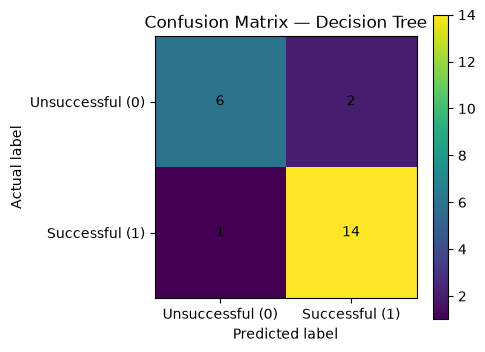

In [11]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_name]
y_pred = best_model.predict(X_test)

print("Best baseline model by F1 score:", best_name)
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.xticks([0, 1], ["Unsuccessful (0)", "Successful (1)"])
plt.yticks([0, 1], ["Unsuccessful (0)", "Successful (1)"])
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.colorbar()
plt.tight_layout()
plt.show()

## 10. Key findings — fill in after running

Use the actual tables and charts generated above to write your conclusions. Example prompts:

- How many launches and successful landings are present?
- Which launch site has the highest observed success rate, and how many launches does it have?
- Does payload mass appear to differ by landing outcome?
- Which baseline model performed best on the test set, and what were its precision, recall, and F1 score?
- What limitations should readers keep in mind?

**Limitations to discuss**
- The dataset is relatively small and may not represent all future launches.
- Launch outcomes are influenced by many operational factors that may not appear in the dataset.
- A model trained on historical data may not generalize to changed launch conditions.
- This notebook is a baseline workflow; it does not replace the full set of IBM labs (web scraping, SQL, Folium, and Plotly Dash).


## 11. Save the prepared dataset and model results

This cell exports the cleaned data and the model comparison table to the current working folder. These files can be used when preparing your final report.


In [12]:
data.to_csv("spacex_cleaned_data.csv", index=False)
results_df.to_csv("spacex_model_comparison.csv", index=False)

print("Saved:")
print("- spacex_cleaned_data.csv")
print("- spacex_model_comparison.csv")

Saved:
- spacex_cleaned_data.csv
- spacex_model_comparison.csv


## 12. Next steps for the complete capstone

This starter notebook covers basic data loading, EDA, and classification. To meet the complete IBM rubric, continue with separate work for:
1. SpaceX API data collection.
2. Web scraping of historical launch records.
3. SQL-based exploratory analysis.
4. Interactive Folium map and launch-site proximity analysis.
5. Plotly Dash dashboard.
6. A final presentation exported to `Data Science Capstone Project Report.pdf`.

Reference the official course instructions and cite your own GitHub repository in the presentation.
